# Lesson 9.2: Assumptions and Normality: Can I Trust This Test?

Check normality with the Shapiro-Wilk test and a normal Q-Q plot for two samples of 20 values from the lesson, one roughly normal (exam scores) and one skewed (response times).

Part of *Statistics from Scratch*. Run each cell with **Shift + Enter**, top to bottom.

If a package is missing on your computer, run the next cell once. In Google Colab everything is already installed.

In [ ]:
%pip install -q numpy scipy pandas statsmodels matplotlib

## 1. Enter the two samples

Exam scores look roughly bell-shaped. Response times have a long tail of a few very slow values. A look at the mean versus the median already hints at the difference.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

exam = np.array([62, 65, 68, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 83, 85, 87, 90, 94])
resp = np.array([1.2, 1.4, 1.5, 1.7, 1.9, 2.0, 2.2, 2.3, 2.6, 2.8, 3.1, 3.5, 3.9, 4.6, 5.4, 6.8, 8.9, 12.5, 18.7, 31.2])

for name, x in [('exam scores', exam), ('response times', resp)]:
    print(f'{name:15s} mean = {x.mean():.2f}, median = {np.median(x):.2f}')

exam scores     mean = 77.05, median = 76.50
response times  mean = 5.91, median = 2.95


## 2. Shapiro-Wilk test of normality

Shapiro-Wilk starts from the assumption that the data are normal. A small p-value (below 0.05) is evidence against normality; a large one only means we found no evidence against it.

In [2]:
for name, x in [('exam scores', exam), ('response times', resp)]:
    w = stats.shapiro(x)
    p_text = f'{w.pvalue:.4f}' if w.pvalue >= 0.0001 else '< 0.0001'
    verdict = 'no evidence against normality' if w.pvalue >= 0.05 else 'evidence of non-normality'
    print(f'{name:15s} W = {w.statistic:.3f}, p = {p_text}  ->  {verdict}')

exam scores     W = 0.993, p = 0.9998  ->  no evidence against normality
response times  W = 0.641, p = < 0.0001  ->  evidence of non-normality


## 3. Draw the normal Q-Q plots

A Q-Q plot lines up the sorted data against what a normal sample would give. Points close to the straight line mean roughly normal; a curve that bends away, as with the response times, signals skew.

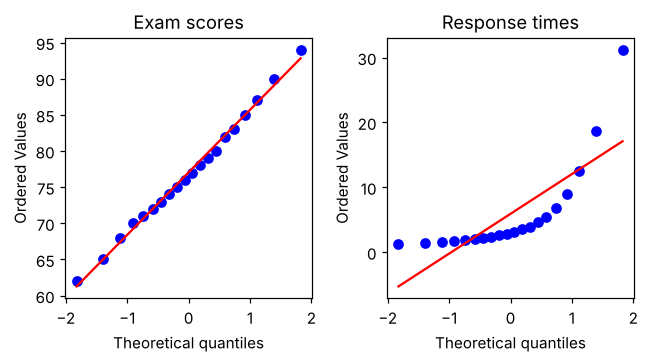

In [3]:
plt.figure(figsize=(6, 3.4))
plt.subplot(1, 2, 1)
stats.probplot(exam, dist='norm', plot=plt)
plt.title('Exam scores')
plt.subplot(1, 2, 2)
stats.probplot(resp, dist='norm', plot=plt)
plt.title('Response times')
plt.tight_layout()
plt.show()

## Try this

- Replace the largest response time (31.2) with 6.0. Predict whether W moves toward 1 or away, then run it.
- Take the logarithm of the response times (np.log) and run Shapiro-Wilk again. Does the skew go away?

## The same idea in R, SPSS and Stata

**R**

```r
exam <- c(62, 65, 68, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 82, 83, 85, 87, 90, 94)
resp <- c(1.2, 1.4, 1.5, 1.7, 1.9, 2.0, 2.2, 2.3, 2.6, 2.8, 3.1, 3.5, 3.9, 4.6, 5.4, 6.8, 8.9, 12.5, 18.7, 31.2)
shapiro.test(exam)
shapiro.test(resp)
par(mfrow = c(1, 2))
qqnorm(exam, main = "Exam scores"); qqline(exam)
qqnorm(resp, main = "Response times"); qqline(resp)
```

**SPSS** (Analyze > Descriptive Statistics > Explore (Plots: Normality plots with tests))

```
DATA LIST FREE / exam resp.
BEGIN DATA
62 1.2  65 1.4  68 1.5  70 1.7  71 1.9  72 2.0  73 2.2  74 2.3  75 2.6  76 2.8
77 3.1  78 3.5  79 3.9  80 4.6  82 5.4  83 6.8  85 8.9  87 12.5  90 18.7  94 31.2
END DATA.
EXAMINE VARIABLES=exam resp
  /PLOT=NPPLOT
  /STATISTICS=NONE.
```

**Stata**

```
clear
set obs 20
generate exam = real(word("62 65 68 70 71 72 73 74 75 76 77 78 79 80 82 83 85 87 90 94", _n))
generate resp = real(word("1.2 1.4 1.5 1.7 1.9 2.0 2.2 2.3 2.6 2.8 3.1 3.5 3.9 4.6 5.4 6.8 8.9 12.5 18.7 31.2", _n))
swilk exam resp
qnorm exam
qnorm resp
```